# Mortality exploration (Step 2)

Exploring Canadian period life-table mortality before building the premium model.

- **Source:** Statistics Canada Table 13-10-0114-01, cleaned by `src/clean_data.py` into `data/qx_clean.csv`
- **Main period:** Canada, 2022/2024 (a three-year *period* table: a snapshot, not a forecast)
- **Educational illustration.** Patterns below describe the population table and do not imply causation.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from survival_model import load_qx, survival_probs

PATH = "../data/qx_clean.csv"
PERIOD = "2022/2024"
df = pd.read_csv(PATH)
qm = load_qx(PATH, "Canada", "Males", PERIOD)
qf = load_qx(PATH, "Canada", "Females", PERIOD)
print(df.shape)
df.head()

(143190, 5)


,period,geo,sex,age,qx
0,1980/1982,Alberta,Both sexes,0,0.01120
1,1980/1982,Alberta,Both sexes,1,0.00074
2,1980/1982,Alberta,Both sexes,2,0.00057
3,1980/1982,Alberta,Both sexes,3,0.00046
4,1980/1982,Alberta,Both sexes,4,0.00038


## 1. Data checks

In [2]:
print("periods:", df.period.nunique(), "|", df.period.min(), "to", df.period.max())
print("geographies:", sorted(df.geo.unique()))
print("sexes:", sorted(df.sex.unique()))
print("ages:", df.age.min(), "to", df.age.max())
print("missing qx:", df.qx.isna().sum())
print("duplicates:", df.duplicated(["period", "geo", "sex", "age"]).sum())
print("qx outside [0,1]:", ((df.qx < 0) | (df.qx > 1)).sum())
print("ages per Canada/2022-2024/male series:", len(qm))

periods: 43 | 1980/1982 to 2022/2024
geographies: ['Alberta', 'British Columbia', 'Canada', 'Manitoba', 'New Brunswick', 'Newfoundland and Labrador', 'Nova Scotia', 'Ontario', 'Quebec', 'Saskatchewan']
sexes: ['Both sexes', 'Females', 'Males']
ages: 0 to 110
missing qx: 0
duplicates: 0
qx outside [0,1]: 0
ages per Canada/2022-2024/male series: 111


## 2. qx by age, by sex

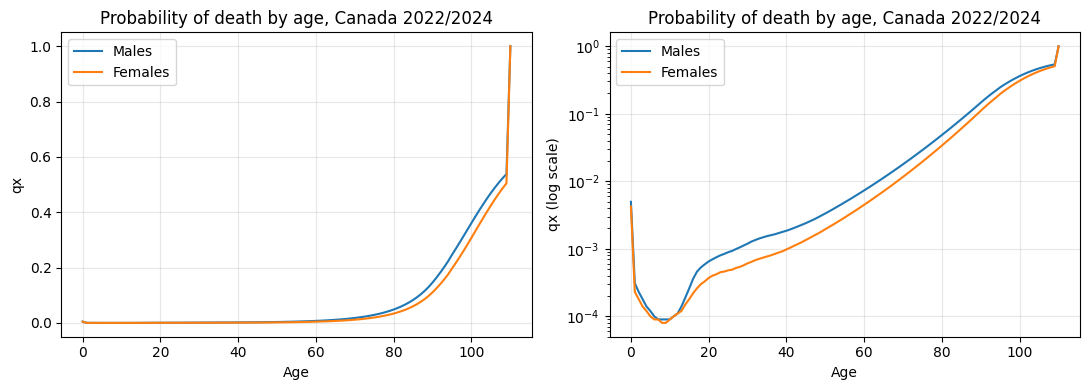

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(qm.index, qm.values, label="Males")
    ax.plot(qf.index, qf.values, label="Females")
    ax.set(xlabel="Age", ylabel="qx" + (" (log scale)" if scale == "log" else ""), yscale=scale,
           title=f"Probability of death by age, Canada {PERIOD}")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

On the log scale, qx is high in infancy, drops to a minimum in childhood, rises through young adulthood, then climbs close to a straight line through the middle ages (roughly exponential growth). qx reaches 1.0 at age 110, which is where the table closes out. Old-age values are the least reliable because data there are sparse.

## 3. Selected ages: 25, 35, 45, 55

In [4]:
ages = [25, 35, 45, 55]
sel = pd.DataFrame({"Male qx": qm.loc[ages], "Female qx": qf.loc[ages]})
sel["Male / Female"] = (sel["Male qx"] / sel["Female qx"]).round(2)
sel

,Male qx,Female qx,Male / Female
age,,,
25,0.00089,0.00048,1.85
35,0.00154,0.00077,2.00
45,0.00240,0.00135,1.78
55,0.00488,0.00291,1.68


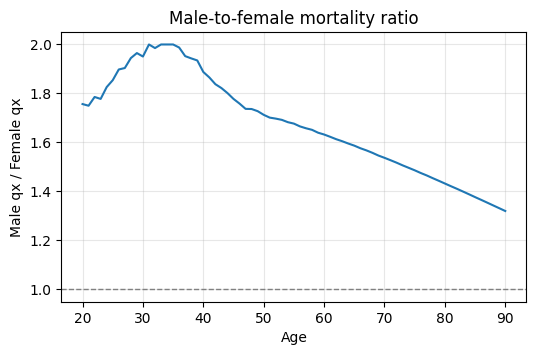

In [5]:
ratio = (qm / qf).loc[20:90]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ratio.index, ratio.values)
ax.axhline(1, color="gray", lw=1, ls="--")
ax.set(xlabel="Age", ylabel="Male qx / Female qx", title="Male-to-female mortality ratio")
ax.grid(alpha=0.3); plt.show()

At the selected ages the male qx is higher than the female qx, by a factor of roughly 1.7 to 2.0. The ratio narrows at older ages. This describes the table; it does not explain the difference.

## 4. 10- and 20-year survival probabilities

In [6]:
rows = []
for a in ages:
    rows.append({"Issue age": a,
                 "Male 10-yr": survival_probs(qm, a, 10)[10], "Male 20-yr": survival_probs(qm, a, 20)[20],
                 "Female 10-yr": survival_probs(qf, a, 10)[10], "Female 20-yr": survival_probs(qf, a, 20)[20]})
surv = pd.DataFrame(rows).set_index("Issue age")
surv.style.format("{:.1%}")

,Male 10-yr,Male 20-yr,Female 10-yr,Female 20-yr
Issue age,,,,
25,98.8%,97.0%,99.4%,98.4%
35,98.2%,95.0%,99.0%,97.1%
45,96.7%,89.9%,98.1%,93.8%
55,93.0%,77.7%,95.6%,85.1%


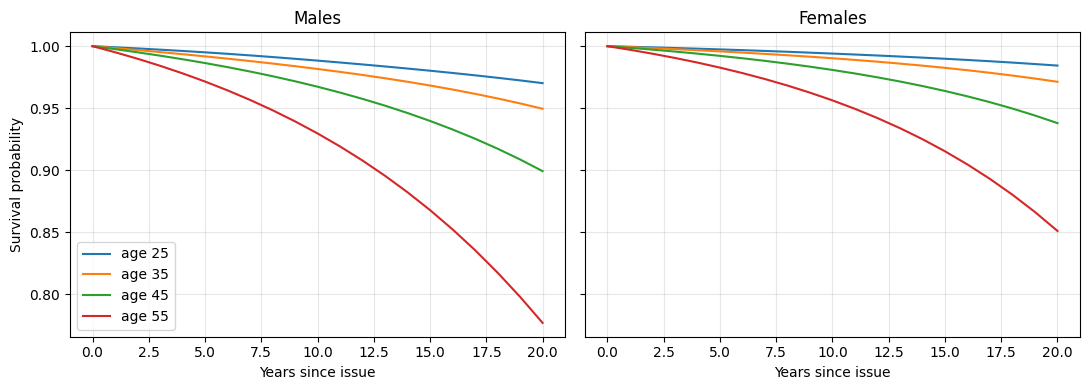

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (q, name) in zip(axes, [(qm, "Males"), (qf, "Females")]):
    for a in ages:
        ax.plot(range(0, 21), survival_probs(q, a, 20), label=f"age {a}")
    ax.set(title=name, xlabel="Years since issue")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Survival probability"); axes[0].legend()
plt.tight_layout(); plt.show()

Survival curves are non-increasing by construction (a running product of 1 - q). They fall faster for older issue ages and for males.

## 5. Across periods (optional)

The table has 43 overlapping three-year windows. Adjacent windows share two years of data, so they are **not independent observations**. The 2020/2022 to 2021/2023 windows include COVID-19 years, which is why the choice of the main period is a judgment.

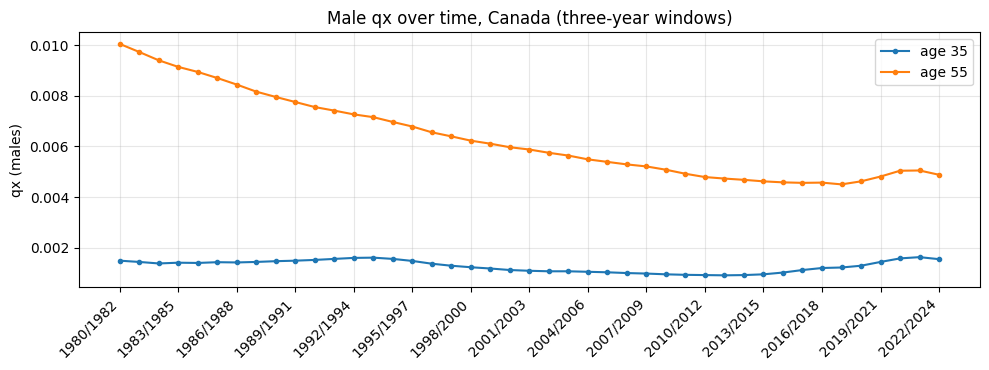

In [8]:
sub = df[(df.geo == "Canada") & (df.sex == "Males") & (df.age.isin([35, 55]))]
piv = sub.pivot(index="period", columns="age", values="qx")
fig, ax = plt.subplots(figsize=(10, 3.8))
for a in [35, 55]:
    ax.plot(range(len(piv)), piv[a].values, marker="o", ms=3, label=f"age {a}")
ax.set_xticks(range(0, len(piv), 3)); ax.set_xticklabels(piv.index[::3], rotation=45, ha="right")
ax.set(ylabel="qx (males)", title="Male qx over time, Canada (three-year windows)")
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

In [9]:
piv.tail(6).round(5)

age,35,55
period,,
2017/2019,0.00121,0.00450
2018/2020,0.00128,0.00462
2019/2021,0.00143,0.00481
2020/2022,0.00157,0.00504
2021/2023,0.00162,0.00505
2022/2024,0.00154,0.00488


## Takeaways

- qx is complete and valid (no missing values, duplicates or out-of-range values), with ages 0 to 110 present.
- Mortality rises steeply with age and is higher for males than females at the ages used for pricing.
- 20-year survival from age 55 is much lower than from age 25, which is what drives the premium differences in the pricing model.
- Population mortality is not insured-life mortality, and a period table does not forecast future mortality.